# Weather Data Visualization

## Objective

Create clear, publication-quality visualizations of district-level weather patterns across India from 2013 to 2024 using preprocessed NASA POWER weather estimates.

## Visualization Scope

- Annual temperature and precipitation trends
- Geographic variation in temperature and rainfall
- Distribution of annual precipitation
- Extreme weather observations and quality-control flags
- Relationships between temperature and precipitation
- Spatial mapping limitations and shared grid points

## Data Source

`data/processed/weather_regional/district_weather_annual_preprocessed_2013_2024.csv`

District and state metadata will be obtained from the corresponding cleaned-and-flagged dataset.

## Interpretation Notes

- Weather measurements are calendar-year summaries, not crop-season measurements.
- Quality-control flags indicate records requiring review; they do not automatically indicate invalid observations.
- Multiple districts can share the same weather grid point.
- Visualized associations do not establish causation.

In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent

weather_path = (
    project_root / "data" / "processed" / "weather_regional" /
    "district_weather_annual_preprocessed_2013_2024.csv"
)

metadata_path = (
    project_root / "data" / "processed" / "weather_regional" /
    "district_weather_annual_cleaned_flagged_2013_2024.csv"
)

weather_df = pd.read_csv(weather_path)

metadata_columns = [
    "apy_geography_id",
    "State",
    "District",
    "nearest_grid_latitude",
    "nearest_grid_longitude",
    "nearest_grid_distance_km"
]

metadata_df = (
    pd.read_csv(metadata_path, usecols=metadata_columns)
    .drop_duplicates(subset=["apy_geography_id"])
)

weather_viz_df = weather_df.merge(
    metadata_df,
    on="apy_geography_id",
    how="left",
    validate="many_to_one"
)

print("Weather data shape:", weather_df.shape)
print("Visualization dataset shape:", weather_viz_df.shape)
print("Unique districts:", weather_viz_df["apy_geography_id"].nunique())
print("Years:", weather_viz_df["calendar_year"].min(),
      "to", weather_viz_df["calendar_year"].max())
print("Missing state/district metadata:",
      weather_viz_df[["State", "District"]].isna().sum().to_dict())

display(weather_viz_df.head())


Weather data shape: (7680, 17)
Visualization dataset shape: (7680, 22)
Unique districts: 640
Years: 2013 to 2024
Missing state/district metadata: {'State': 0, 'District': 0}


,apy_geography_id,calendar_year,tmin_mean_c,tmin_min_c,tmax_mean_c,tmax_max_c,precipitation_total_mm,precipitation_mean_mm_day,precipitation_max_mm_day,tmin_valid_days,...,QC_Extreme_Annual_Min_Temperature,QC_Extreme_Annual_Max_Temperature,QC_High_Annual_Precipitation,QC_Extreme_Daily_Precipitation,QC_Long_District_Grid_Distance,State,District,nearest_grid_latitude,nearest_grid_longitude,nearest_grid_distance_km
0,APY-GEO-0001,2013,27.472904,25.78,28.279671,30.11,2456.73,6.730767,29.00,365,...,False,False,False,False,False,Andaman And Nicobar Islands,Nicobars,7.0,93.75,8.129723
1,APY-GEO-0001,2014,27.517479,25.74,28.430301,30.75,1972.96,5.405370,51.98,365,...,False,False,False,False,False,Andaman And Nicobar Islands,Nicobars,7.0,93.75,8.129723
2,APY-GEO-0001,2015,27.664959,26.03,28.533370,30.15,1767.49,4.842438,36.97,365,...,False,False,False,False,False,Andaman And Nicobar Islands,Nicobars,7.0,93.75,8.129723
3,APY-GEO-0001,2016,27.918333,25.43,28.810492,31.98,2187.42,5.976557,52.15,366,...,False,False,False,False,False,Andaman And Nicobar Islands,Nicobars,7.0,93.75,8.129723
4,APY-GEO-0001,2017,27.570219,25.54,28.360055,29.62,2155.98,5.906795,48.42,365,...,False,False,False,False,False,Andaman And Nicobar Islands,Nicobars,7.0,93.75,8.129723


In [2]:

# Cell 3: Visualization settings

sns.set_theme(style="whitegrid", context="notebook", palette="deep")

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 17
})

print("Visualization style configured.")


Visualization style configured.


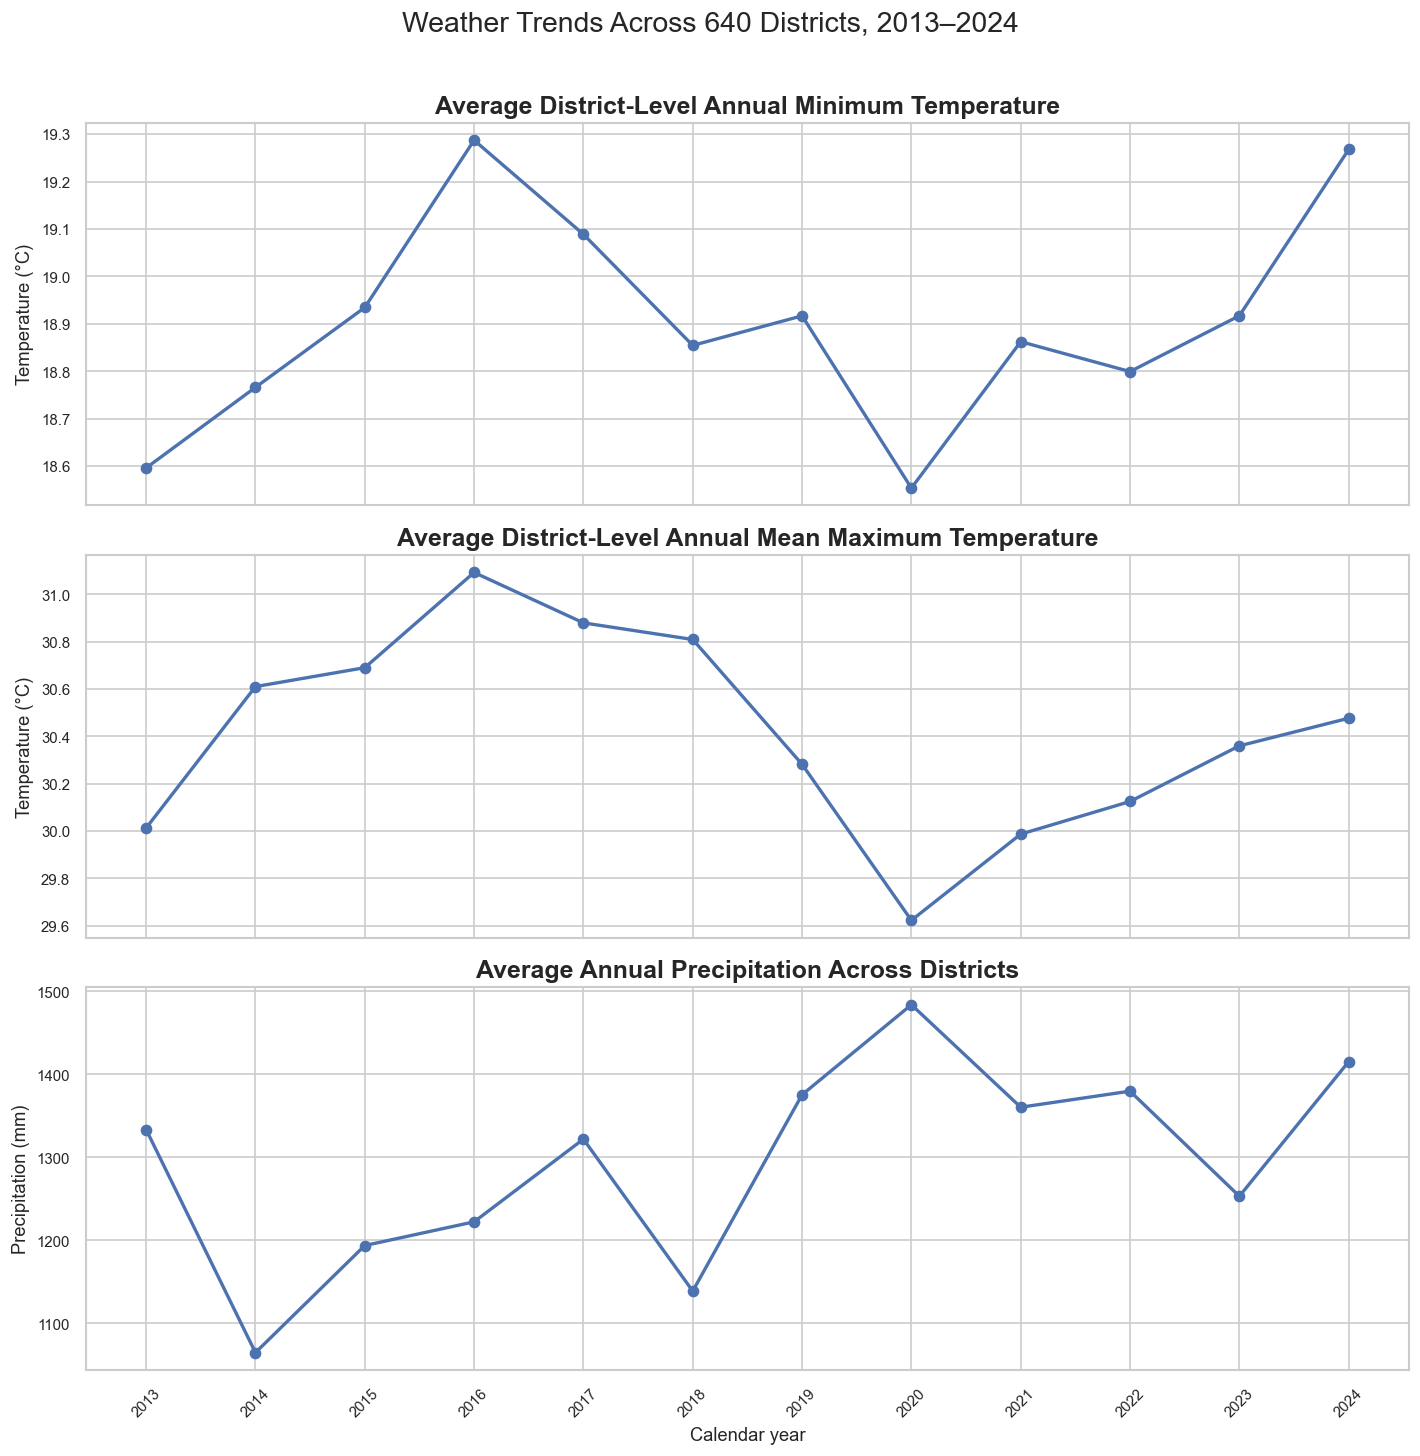

In [3]:

# Cell 4: Annual weather trends

annual_weather_viz = (
    weather_viz_df.groupby("calendar_year")
    .agg(
        mean_min_temp=("tmin_mean_c", "mean"),
        mean_max_temp=("tmax_mean_c", "mean"),
        mean_annual_precip=("precipitation_total_mm", "mean")
    )
    .reset_index()
)

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

axes[0].plot(
    annual_weather_viz["calendar_year"],
    annual_weather_viz["mean_min_temp"],
    marker="o",
    linewidth=2
)
axes[0].set_title("Average District-Level Annual Minimum Temperature")
axes[0].set_ylabel("Temperature (°C)")

axes[1].plot(
    annual_weather_viz["calendar_year"],
    annual_weather_viz["mean_max_temp"],
    marker="o",
    linewidth=2
)
axes[1].set_title("Average District-Level Annual Mean Maximum Temperature")
axes[1].set_ylabel("Temperature (°C)")

axes[2].plot(
    annual_weather_viz["calendar_year"],
    annual_weather_viz["mean_annual_precip"],
    marker="o",
    linewidth=2
)
axes[2].set_title("Average Annual Precipitation Across Districts")
axes[2].set_ylabel("Precipitation (mm)")
axes[2].set_xlabel("Calendar year")

for ax in axes:
    ax.set_xticks(annual_weather_viz["calendar_year"])
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Weather Trends Across 640 Districts, 2013–2024", y=1.01)
plt.tight_layout()
plt.show()


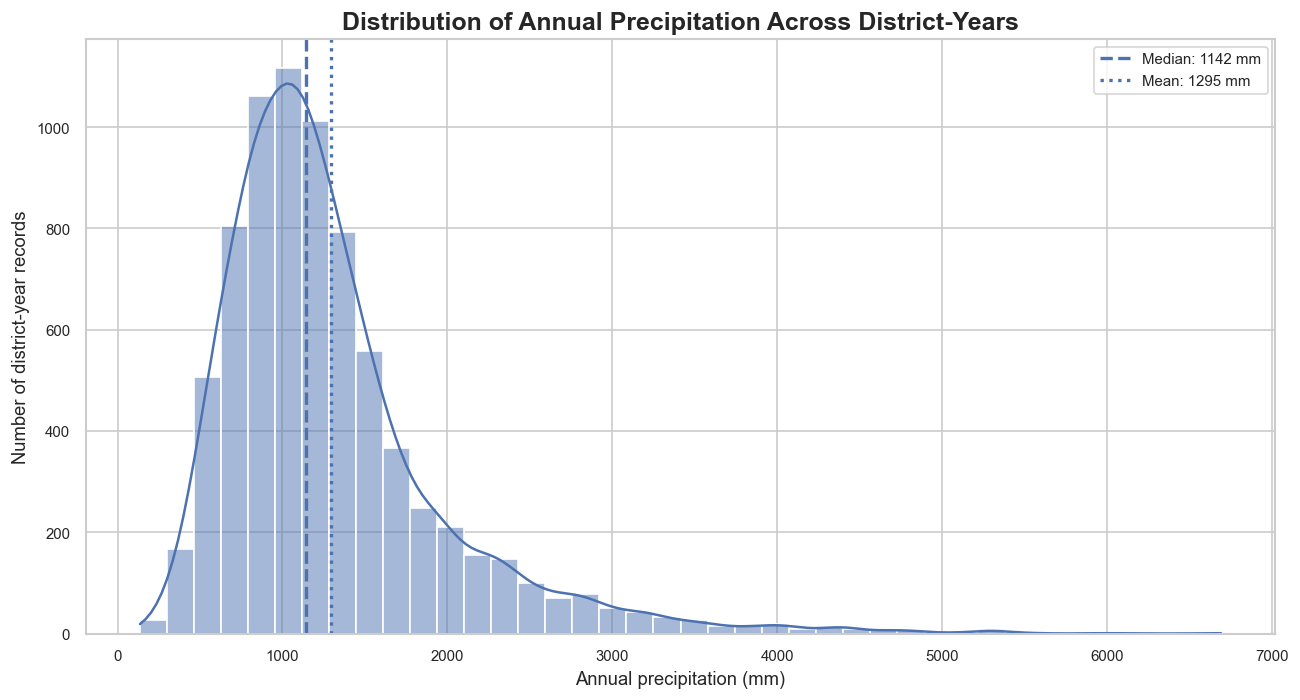

In [4]:

# Cell 5: Distribution of annual precipitation

precipitation = weather_viz_df["precipitation_total_mm"]
median_precipitation = precipitation.median()
mean_precipitation = precipitation.mean()

plt.figure(figsize=(11, 6))

sns.histplot(
    precipitation,
    bins=40,
    kde=True
)

plt.axvline(
    median_precipitation,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_precipitation:.0f} mm"
)

plt.axvline(
    mean_precipitation,
    linestyle=":",
    linewidth=2,
    label=f"Mean: {mean_precipitation:.0f} mm"
)

plt.title("Distribution of Annual Precipitation Across District-Years")
plt.xlabel("Annual precipitation (mm)")
plt.ylabel("Number of district-year records")
plt.legend()
plt.tight_layout()
plt.show()


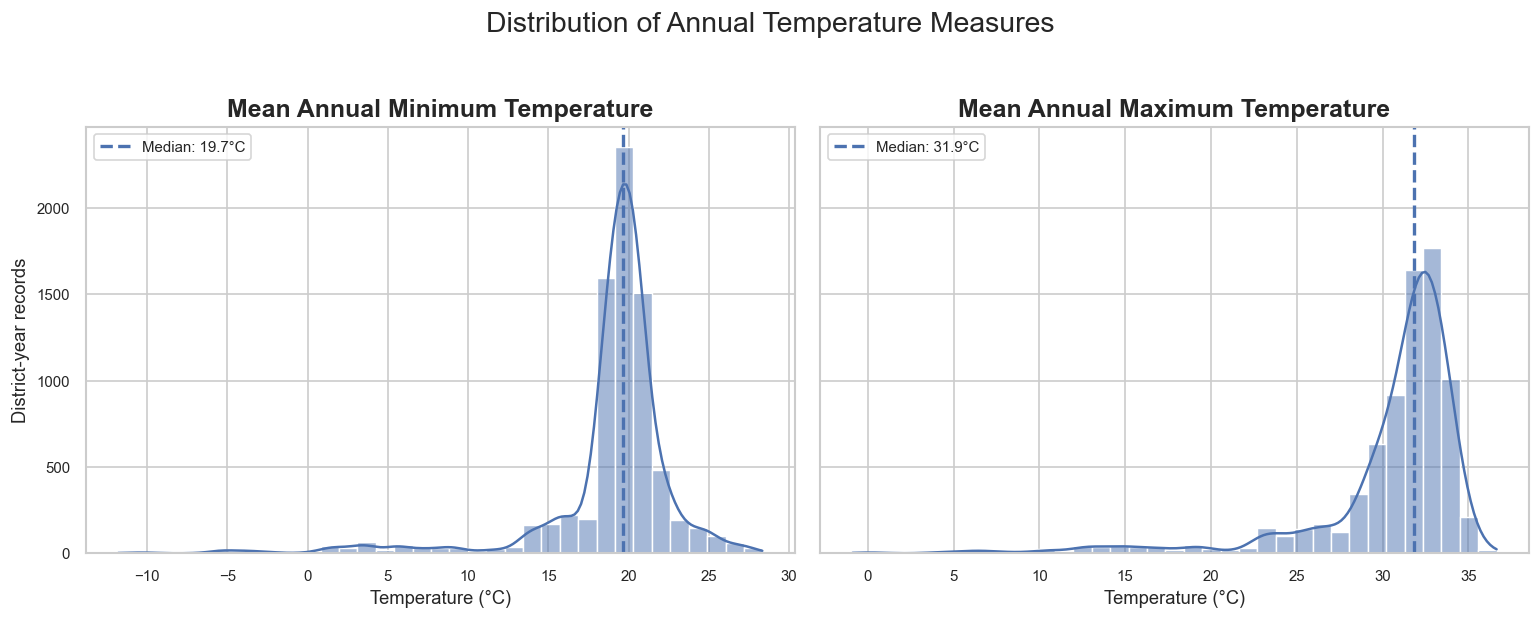

In [5]:

# Cell 6: Compare temperature distributions

temperature_long = weather_viz_df[
    ["tmin_mean_c", "tmax_mean_c"]
].melt(
    var_name="temperature_measure",
    value_name="temperature_c"
)

temperature_long["temperature_measure"] = (
    temperature_long["temperature_measure"].map({
        "tmin_mean_c": "Mean Annual Minimum Temperature",
        "tmax_mean_c": "Mean Annual Maximum Temperature"
    })
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, measure in zip(
    axes,
    [
        "Mean Annual Minimum Temperature",
        "Mean Annual Maximum Temperature"
    ]
):
    subset = temperature_long[
        temperature_long["temperature_measure"] == measure
    ]

    sns.histplot(
        data=subset,
        x="temperature_c",
        bins=35,
        kde=True,
        ax=ax
    )

    ax.axvline(
        subset["temperature_c"].median(),
        linestyle="--",
        linewidth=2,
        label=f'Median: {subset["temperature_c"].median():.1f}°C'
    )

    ax.set_title(measure)
    ax.set_xlabel("Temperature (°C)")
    ax.set_ylabel("District-year records")
    ax.legend()

fig.suptitle("Distribution of Annual Temperature Measures", y=1.03)
plt.tight_layout()
plt.show()


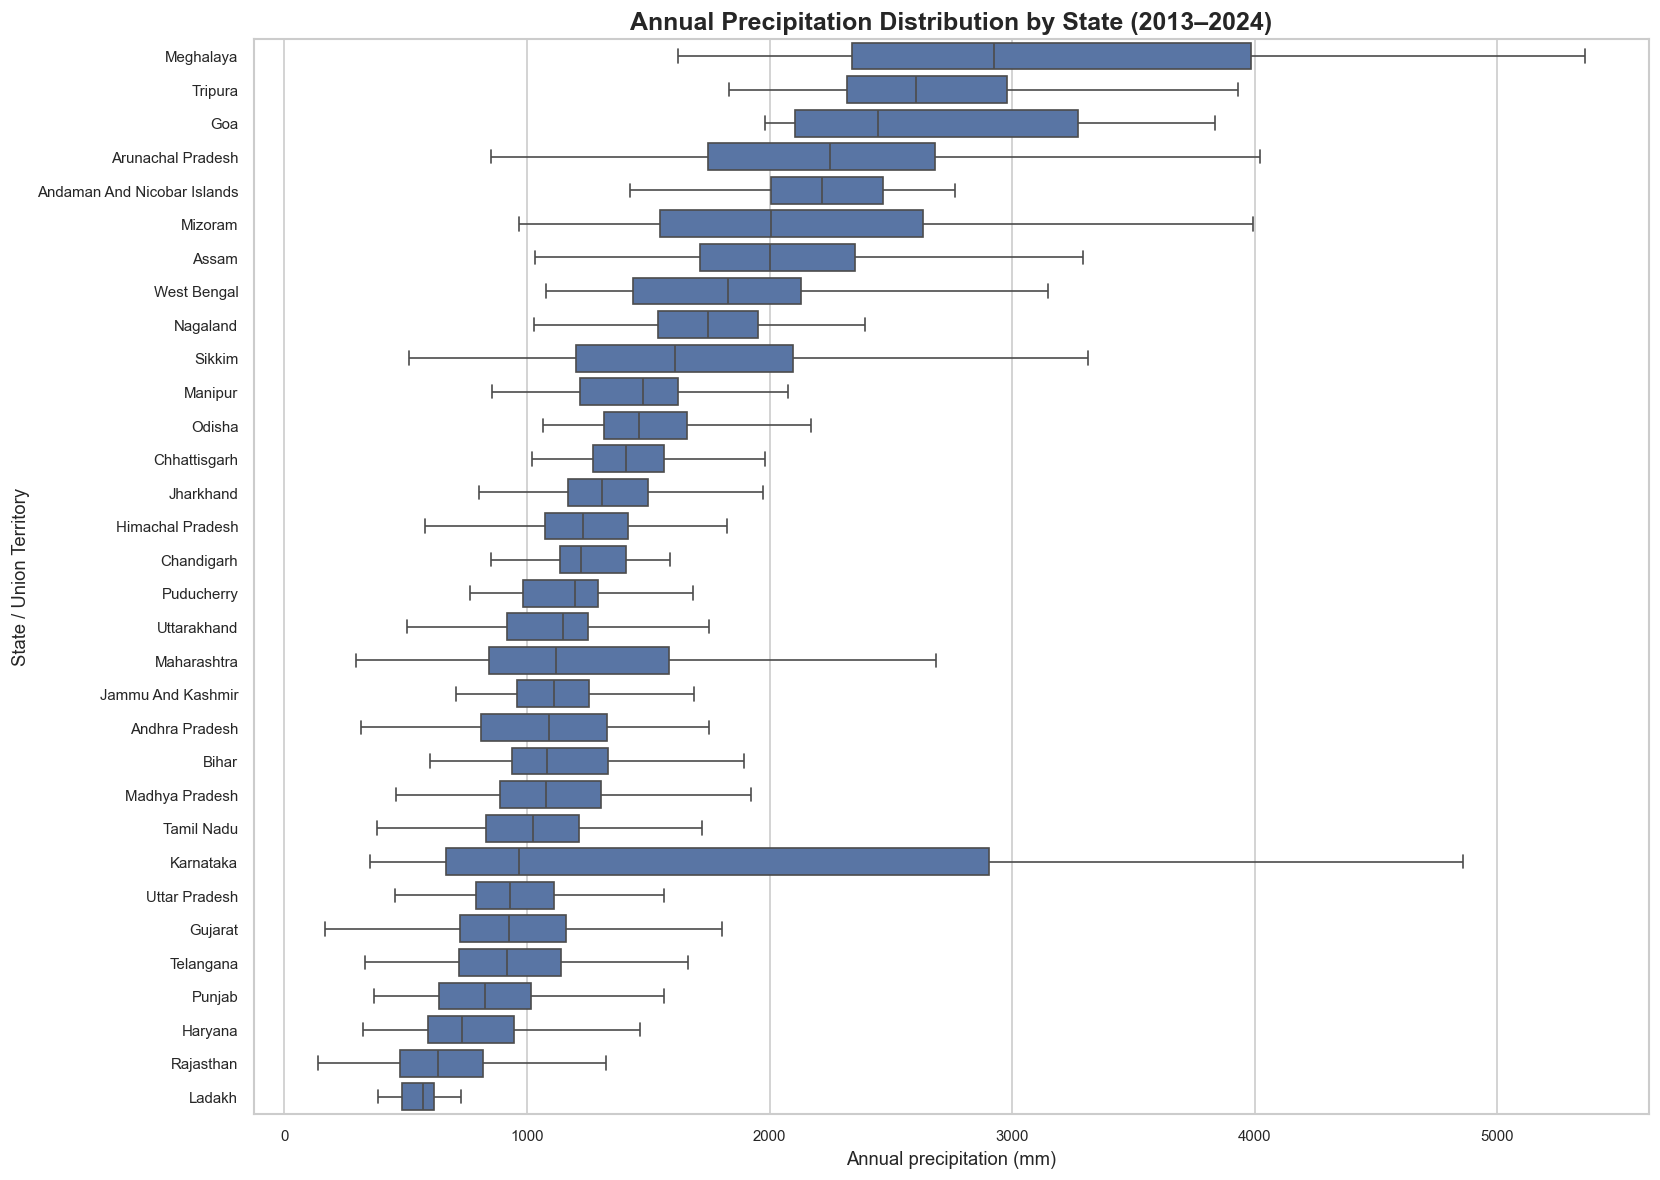

In [6]:

# Cell 7: State-level precipitation distributions

state_order = (
    weather_viz_df.groupby("State")["precipitation_total_mm"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 10))

sns.boxplot(
    data=weather_viz_df,
    y="State",
    x="precipitation_total_mm",
    order=state_order,
    showfliers=False
)

plt.title("Annual Precipitation Distribution by State (2013–2024)")
plt.xlabel("Annual precipitation (mm)")
plt.ylabel("State / Union Territory")
plt.tight_layout()
plt.show()


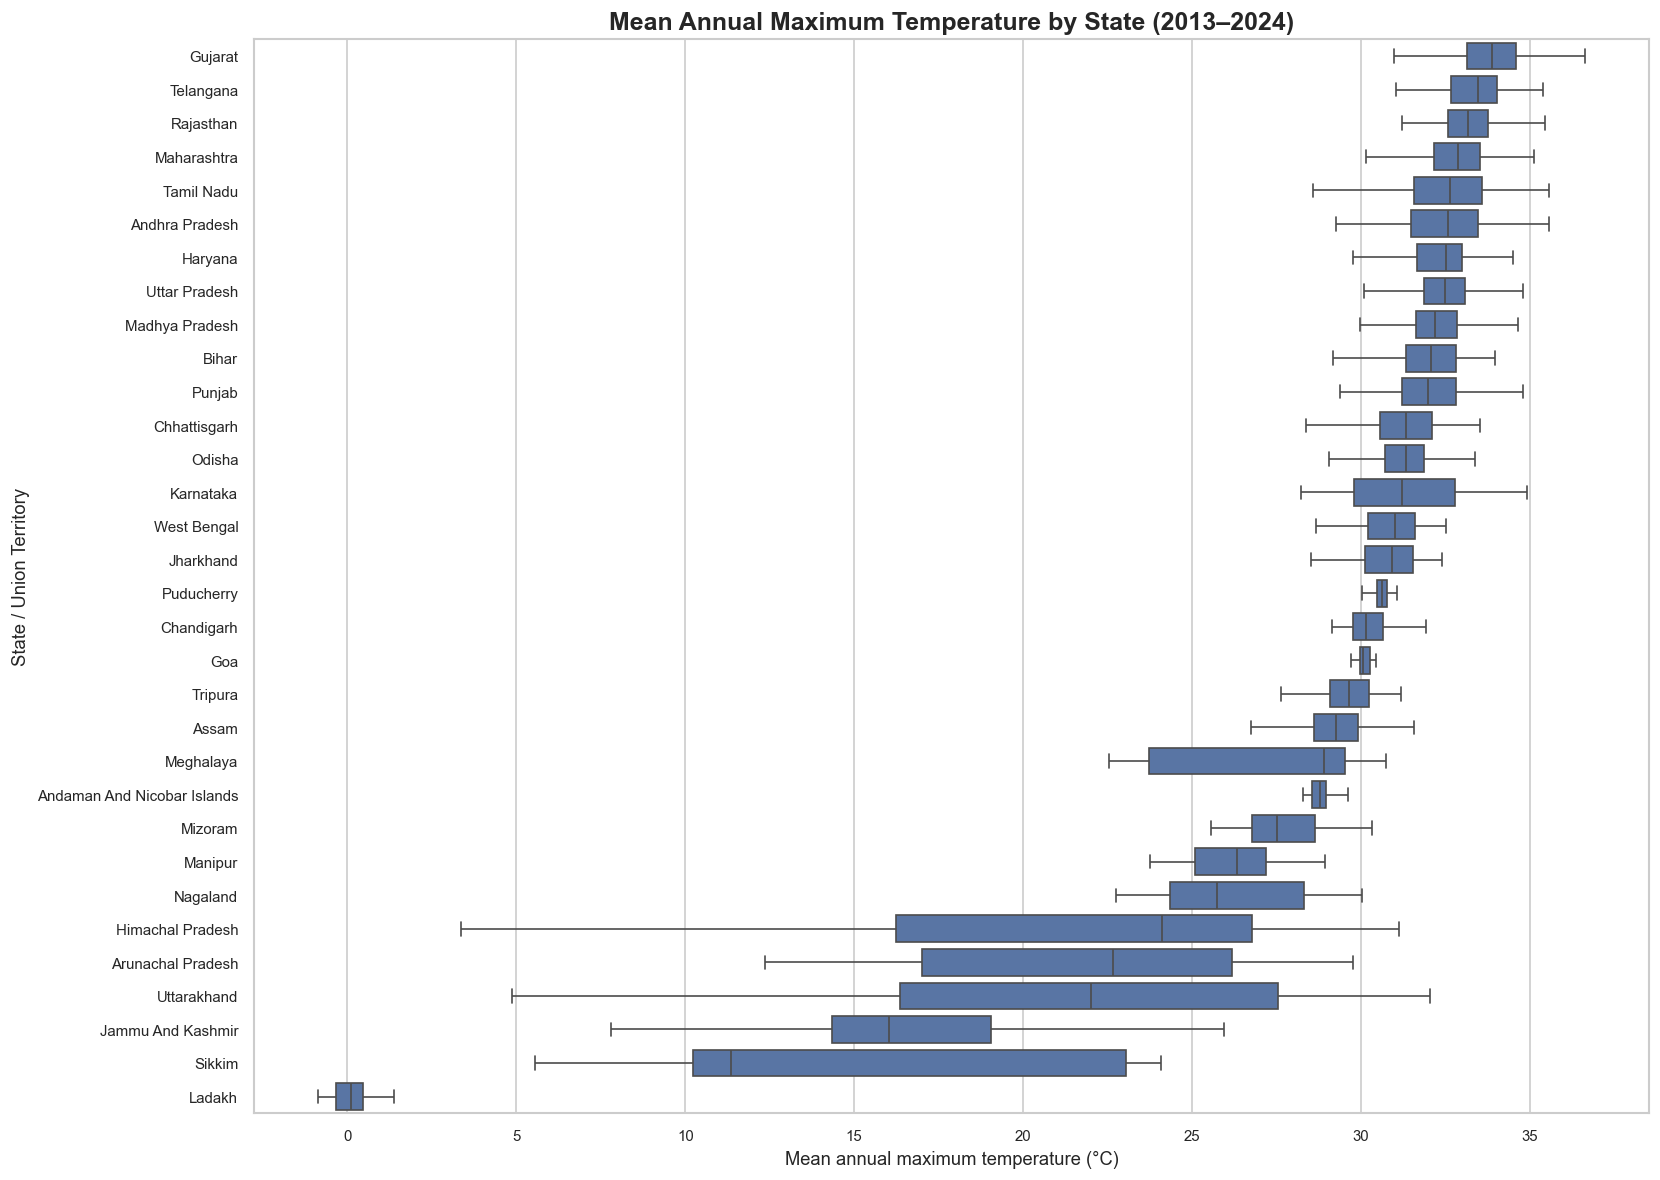

In [7]:

# Cell 8: State-level temperature distributions

temperature_state_order = (
    weather_viz_df.groupby("State")["tmax_mean_c"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 10))

sns.boxplot(
    data=weather_viz_df,
    y="State",
    x="tmax_mean_c",
    order=temperature_state_order,
    showfliers=False
)

plt.title("Mean Annual Maximum Temperature by State (2013–2024)")
plt.xlabel("Mean annual maximum temperature (°C)")
plt.ylabel("State / Union Territory")
plt.tight_layout()
plt.show()


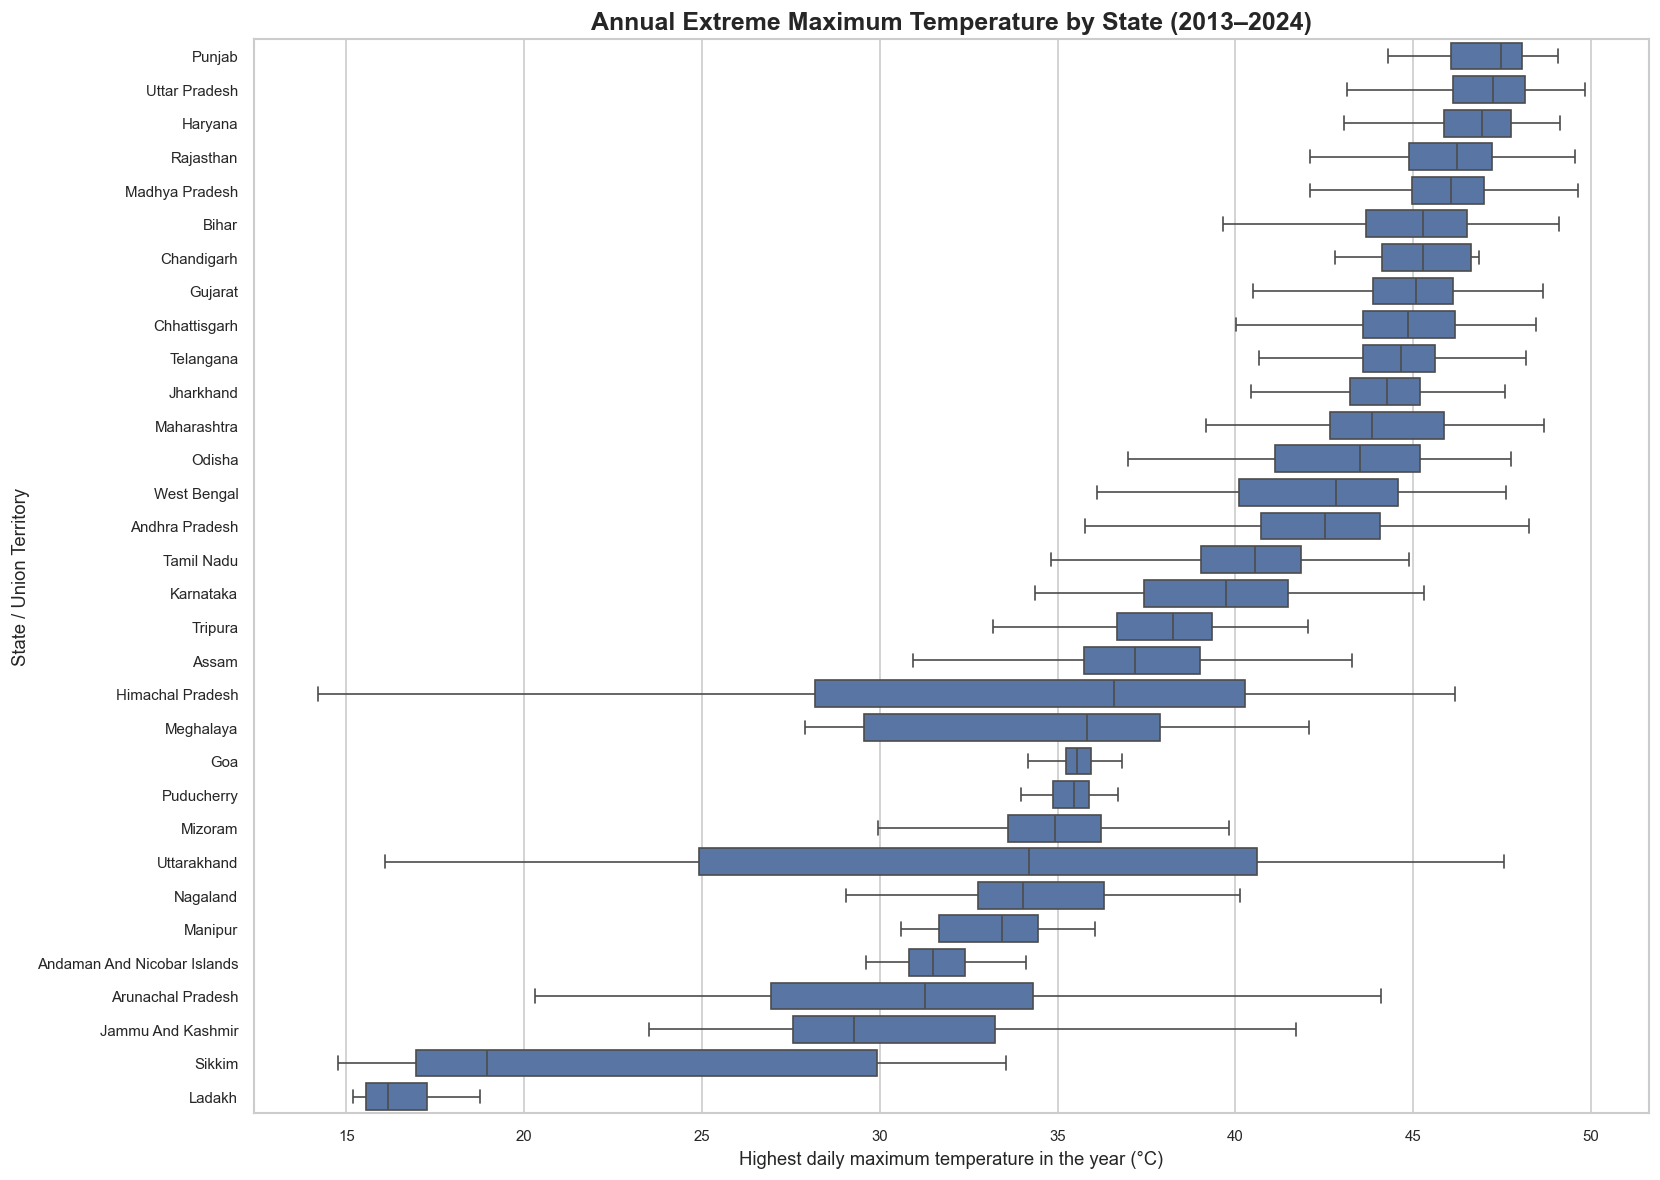

In [8]:

# Cell 9: State-level annual extreme maximum temperatures

extreme_temp_order = (
    weather_viz_df.groupby("State")["tmax_max_c"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 10))

sns.boxplot(
    data=weather_viz_df,
    y="State",
    x="tmax_max_c",
    order=extreme_temp_order,
    showfliers=False
)

plt.title("Annual Extreme Maximum Temperature by State (2013–2024)")
plt.xlabel("Highest daily maximum temperature in the year (°C)")
plt.ylabel("State / Union Territory")
plt.tight_layout()
plt.show()


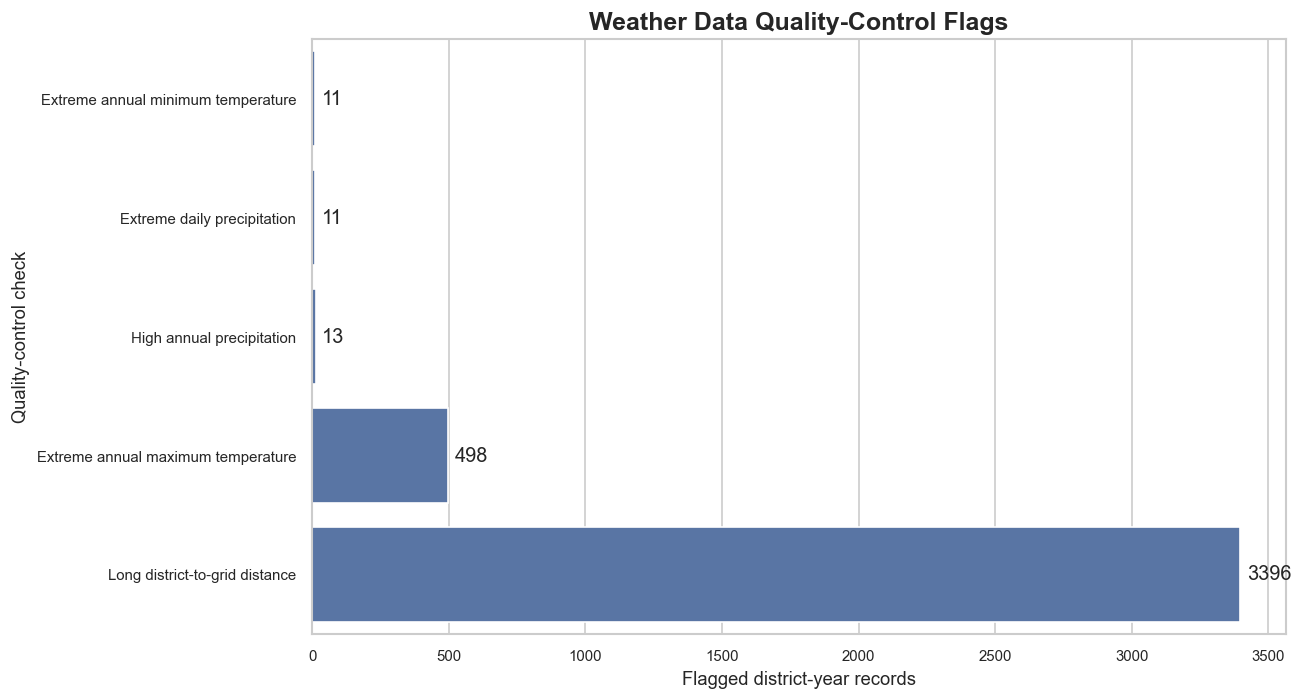

,qc_check,flagged_records
0,Extreme annual minimum temperature,11
3,Extreme daily precipitation,11
2,High annual precipitation,13
1,Extreme annual maximum temperature,498
4,Long district-to-grid distance,3396


In [10]:

# Cell 10: Quality-control flag counts

qc_columns = [
    "QC_Extreme_Annual_Min_Temperature",
    "QC_Extreme_Annual_Max_Temperature",
    "QC_High_Annual_Precipitation",
    "QC_Extreme_Daily_Precipitation",
    "QC_Long_District_Grid_Distance"
]

qc_labels = {
    "QC_Extreme_Annual_Min_Temperature": "Extreme annual minimum temperature",
    "QC_Extreme_Annual_Max_Temperature": "Extreme annual maximum temperature",
    "QC_High_Annual_Precipitation": "High annual precipitation",
    "QC_Extreme_Daily_Precipitation": "Extreme daily precipitation",
    "QC_Long_District_Grid_Distance": "Long district-to-grid distance"
}

qc_summary = (
    weather_viz_df[qc_columns]
    .sum()
    .rename("flagged_records")
    .rename(index=qc_labels)
    .rename_axis("qc_check")
    .reset_index()
    .sort_values("flagged_records")
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=qc_summary,
    x="flagged_records",
    y="qc_check"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)

plt.title("Weather Data Quality-Control Flags")
plt.xlabel("Flagged district-year records")
plt.ylabel("Quality-control check")
plt.tight_layout()
plt.show()

display(qc_summary)


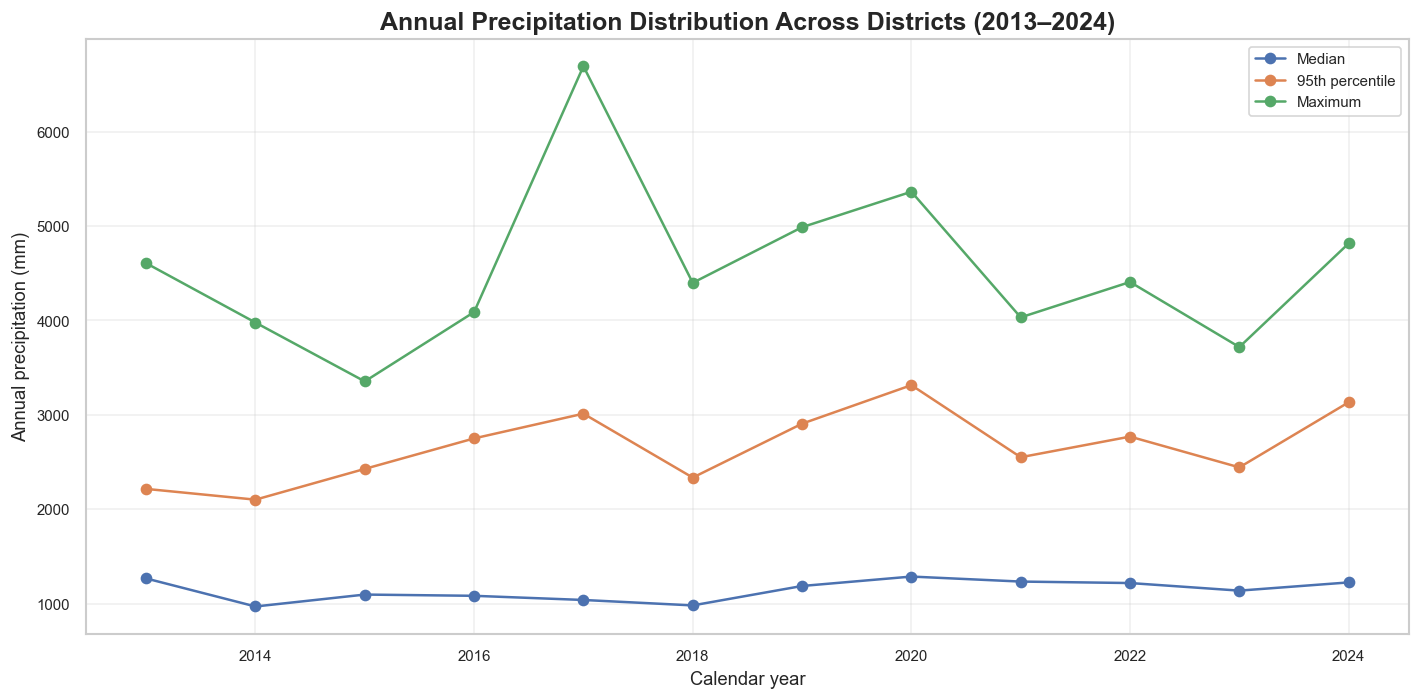

,calendar_year,mean_precipitation_mm,median_precipitation_mm,p95_precipitation_mm,maximum_precipitation_mm
0,2013,1333.58,1265.96,2214.69,4606.13
1,2014,1064.73,968.88,2100.63,3977.14
2,2015,1193.77,1095.18,2426.66,3353.62
3,2016,1222.34,1081.99,2749.69,4088.17
4,2017,1322.01,1037.88,3011.74,6693.07
5,2018,1138.88,980.32,2334.47,4397.91
6,2019,1375.51,1186.10,2905.61,4987.35
7,2020,1484.01,1285.95,3313.91,5363.19
8,2021,1360.47,1232.88,2550.26,4032.02
9,2022,1379.84,1217.29,2768.69,4406.86


In [11]:

# Cell 11: Annual precipitation extremes

annual_precip_extremes = (
    weather_viz_df.groupby("calendar_year")
    .agg(
        mean_precipitation_mm=("precipitation_total_mm", "mean"),
        median_precipitation_mm=("precipitation_total_mm", "median"),
        p95_precipitation_mm=(
            "precipitation_total_mm",
            lambda x: x.quantile(0.95)
        ),
        maximum_precipitation_mm=("precipitation_total_mm", "max")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    annual_precip_extremes["calendar_year"],
    annual_precip_extremes["median_precipitation_mm"],
    marker="o",
    label="Median"
)

ax.plot(
    annual_precip_extremes["calendar_year"],
    annual_precip_extremes["p95_precipitation_mm"],
    marker="o",
    label="95th percentile"
)

ax.plot(
    annual_precip_extremes["calendar_year"],
    annual_precip_extremes["maximum_precipitation_mm"],
    marker="o",
    label="Maximum"
)

ax.set_title("Annual Precipitation Distribution Across Districts (2013–2024)")
ax.set_xlabel("Calendar year")
ax.set_ylabel("Annual precipitation (mm)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(annual_precip_extremes.round(2))


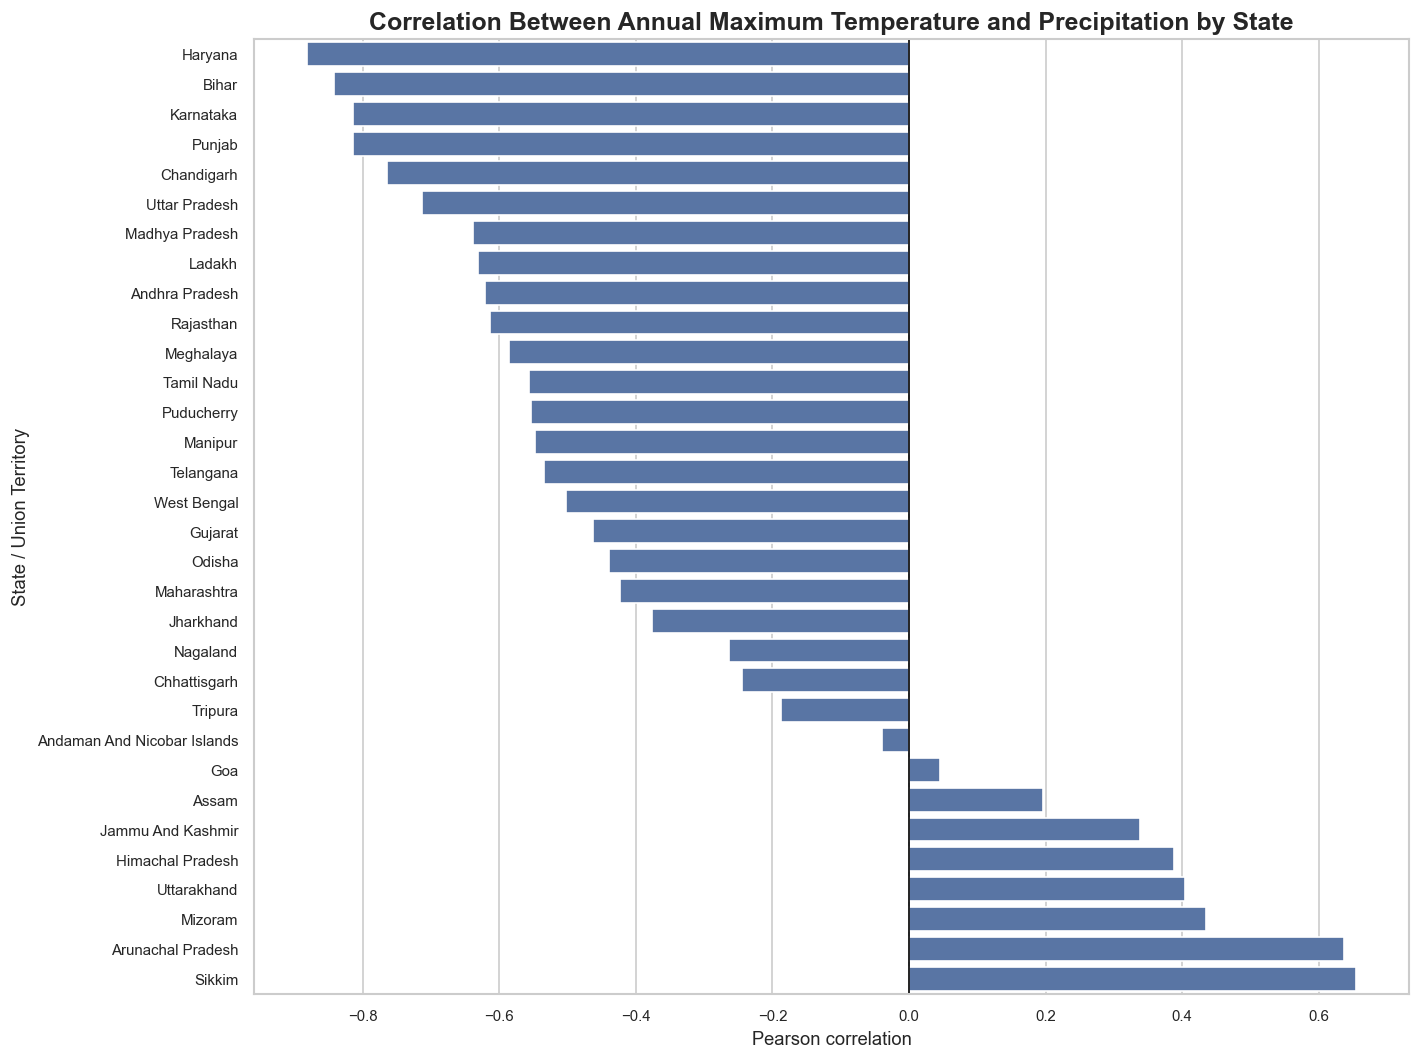

,State,district_year_records,correlation_tmax_precipitation
9,Haryana,252.0,-0.882
4,Bihar,444.0,-0.842
13,Karnataka,144.0,-0.815
23,Punjab,240.0,-0.814
5,Chandigarh,12.0,-0.765
29,Uttar Pradesh,900.0,-0.714
15,Madhya Pradesh,636.0,-0.639
14,Ladakh,12.0,-0.631
1,Andhra Pradesh,288.0,-0.622
24,Rajasthan,444.0,-0.614


In [12]:

# Cell 12: State-level temperature–precipitation correlations

state_correlations = (
    weather_viz_df.groupby("State")
    .apply(
        lambda group: pd.Series({
            "district_year_records": len(group),
            "correlation_tmax_precipitation": group[
                "tmax_mean_c"
            ].corr(group["precipitation_total_mm"])
        }),
        include_groups=False
    )
    .reset_index()
    .sort_values("correlation_tmax_precipitation")
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=state_correlations,
    x="correlation_tmax_precipitation",
    y="State"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Correlation Between Annual Maximum Temperature and Precipitation by State")
plt.xlabel("Pearson correlation")
plt.ylabel("State / Union Territory")
plt.tight_layout()
plt.show()

display(state_correlations.round(3))


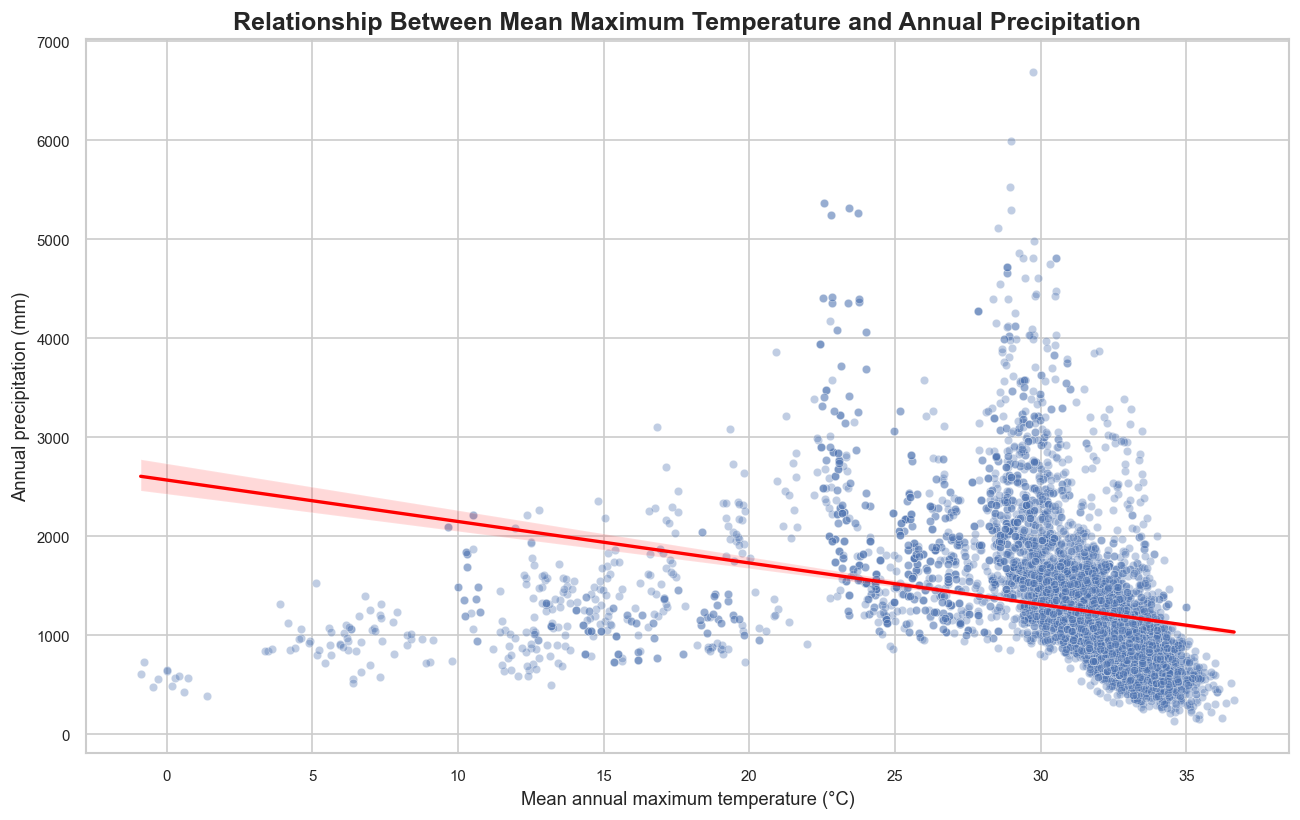

In [13]:

# Cell 13: Temperature vs annual precipitation

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=weather_viz_df,
    x="tmax_mean_c",
    y="precipitation_total_mm",
    alpha=0.35,
    s=25
)

sns.regplot(
    data=weather_viz_df,
    x="tmax_mean_c",
    y="precipitation_total_mm",
    scatter=False,
    color="red",
    line_kws={"linewidth": 2}
)

plt.title("Relationship Between Mean Maximum Temperature and Annual Precipitation")
plt.xlabel("Mean annual maximum temperature (°C)")
plt.ylabel("Annual precipitation (mm)")
plt.tight_layout()
plt.show()


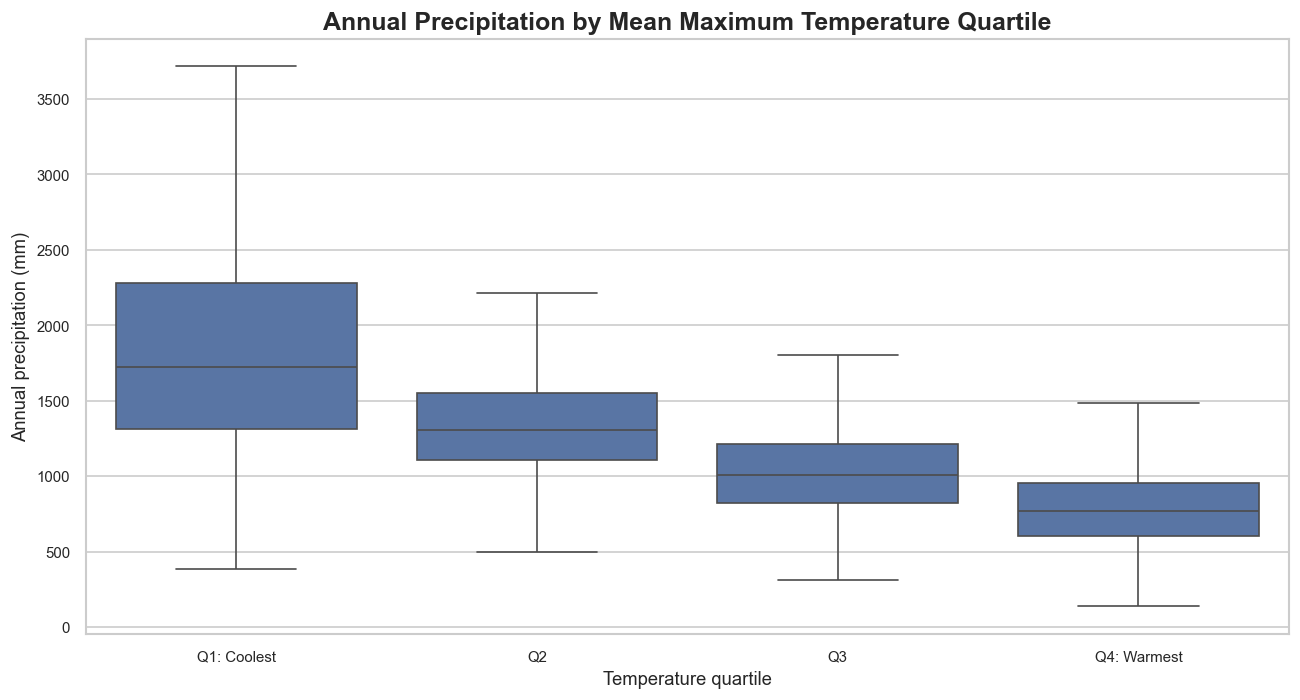

,district_year_records,median_temperature_c,median_precipitation_mm,mean_precipitation_mm
temperature_group,,,,
Q1: Coolest,1921,26.79,1726.21,1894.22
Q2,1919,31.15,1304.21,1418.59
Q3,1920,32.42,1010.48,1052.31
Q4: Warmest,1920,33.63,771.54,815.87


In [14]:

# Cell 14: Precipitation distribution across temperature quartiles

weather_viz_df["temperature_group"] = pd.qcut(
    weather_viz_df["tmax_mean_c"],
    q=4,
    labels=["Q1: Coolest", "Q2", "Q3", "Q4: Warmest"],
    duplicates="drop"
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=weather_viz_df,
    x="temperature_group",
    y="precipitation_total_mm",
    showfliers=False
)

plt.title("Annual Precipitation by Mean Maximum Temperature Quartile")
plt.xlabel("Temperature quartile")
plt.ylabel("Annual precipitation (mm)")
plt.tight_layout()
plt.show()

display(
    weather_viz_df.groupby("temperature_group", observed=True)
    .agg(
        district_year_records=("apy_geography_id", "size"),
        median_temperature_c=("tmax_mean_c", "median"),
        median_precipitation_mm=("precipitation_total_mm", "median"),
        mean_precipitation_mm=("precipitation_total_mm", "mean")
    )
    .round(2)
)


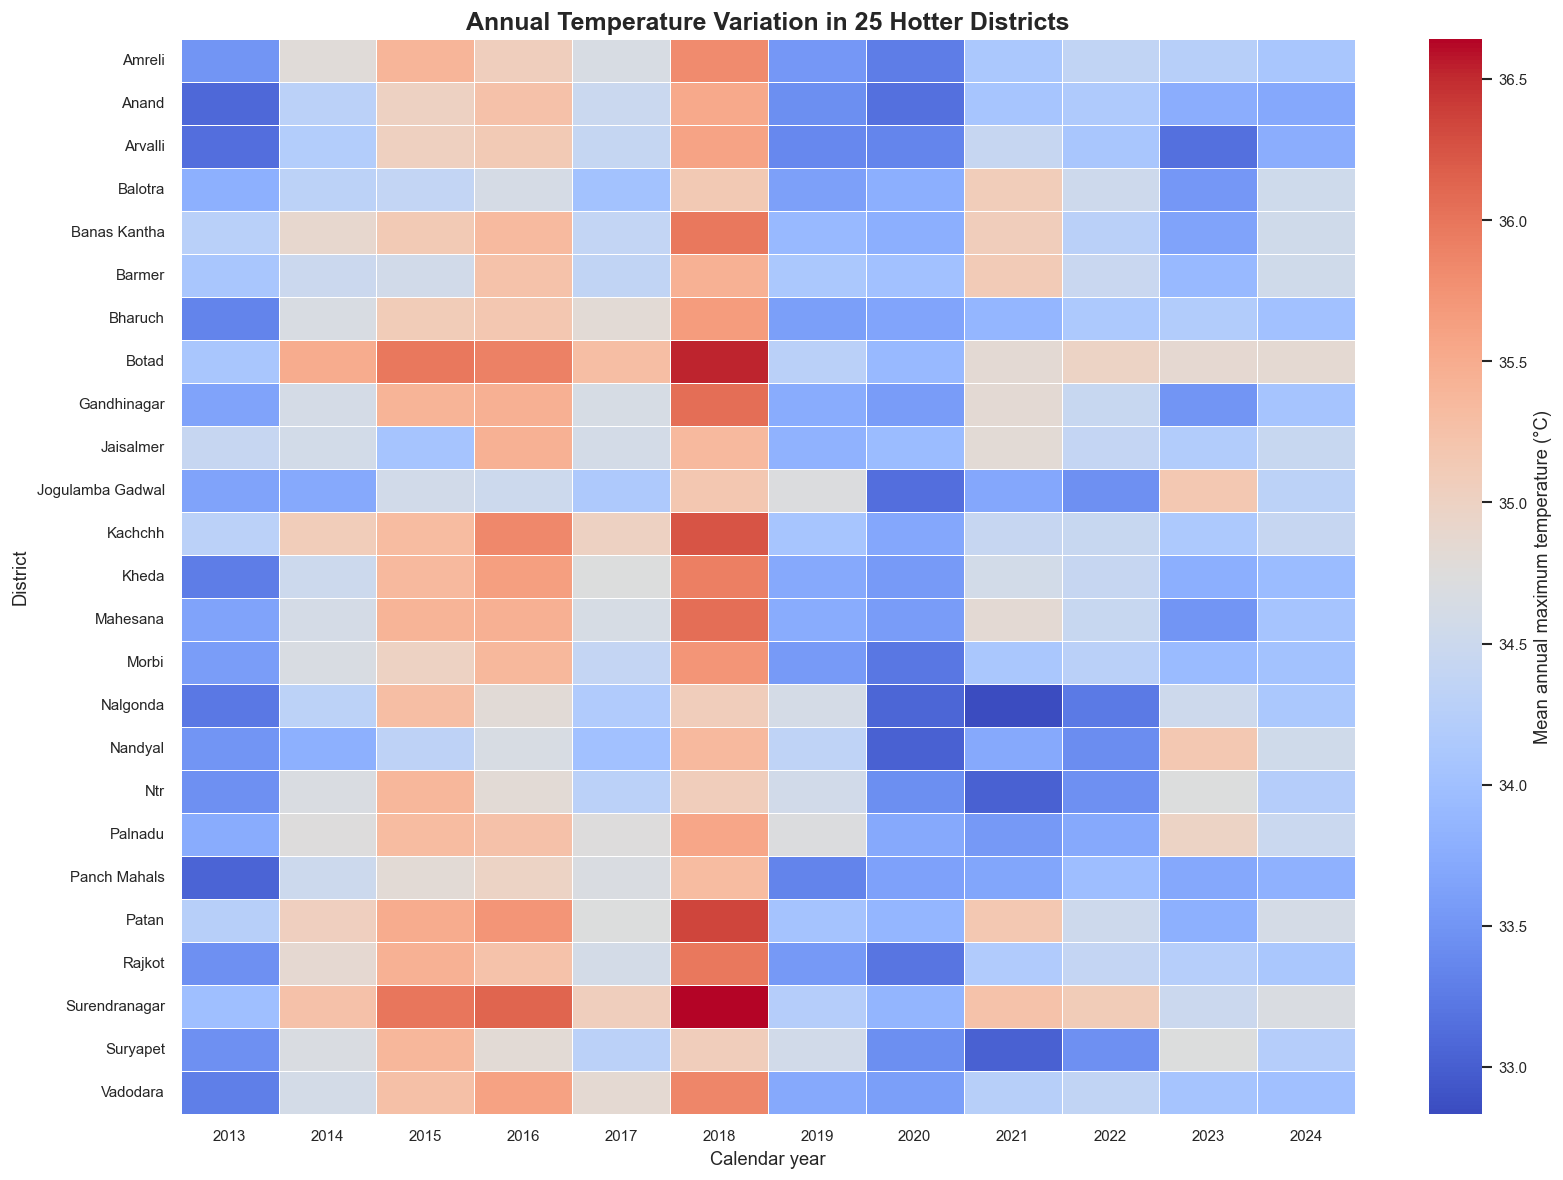

In [17]:

# Cell 15: District-level temperature heatmap

# Select 25 districts with the highest long-term mean maximum temperature.
selected_districts = (
    weather_viz_df.groupby(["State", "District"])["tmax_mean_c"]
    .mean()
    .sort_values(ascending=False)
    .head(25)
    .index
)

heatmap_df = weather_viz_df.set_index(
    ["State", "District"]
).loc[selected_districts].reset_index()

temperature_pivot = heatmap_df.pivot(
    index="District",
    columns="calendar_year",
    values="tmax_mean_c"
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    temperature_pivot,
    cmap="coolwarm",
    linewidths=0.3,
    cbar_kws={"label": "Mean annual maximum temperature (°C)"}
)

plt.title("Annual Temperature Variation in 25 Hotter Districts")
plt.xlabel("Calendar year")
plt.ylabel("District")
plt.tight_layout()
plt.show()


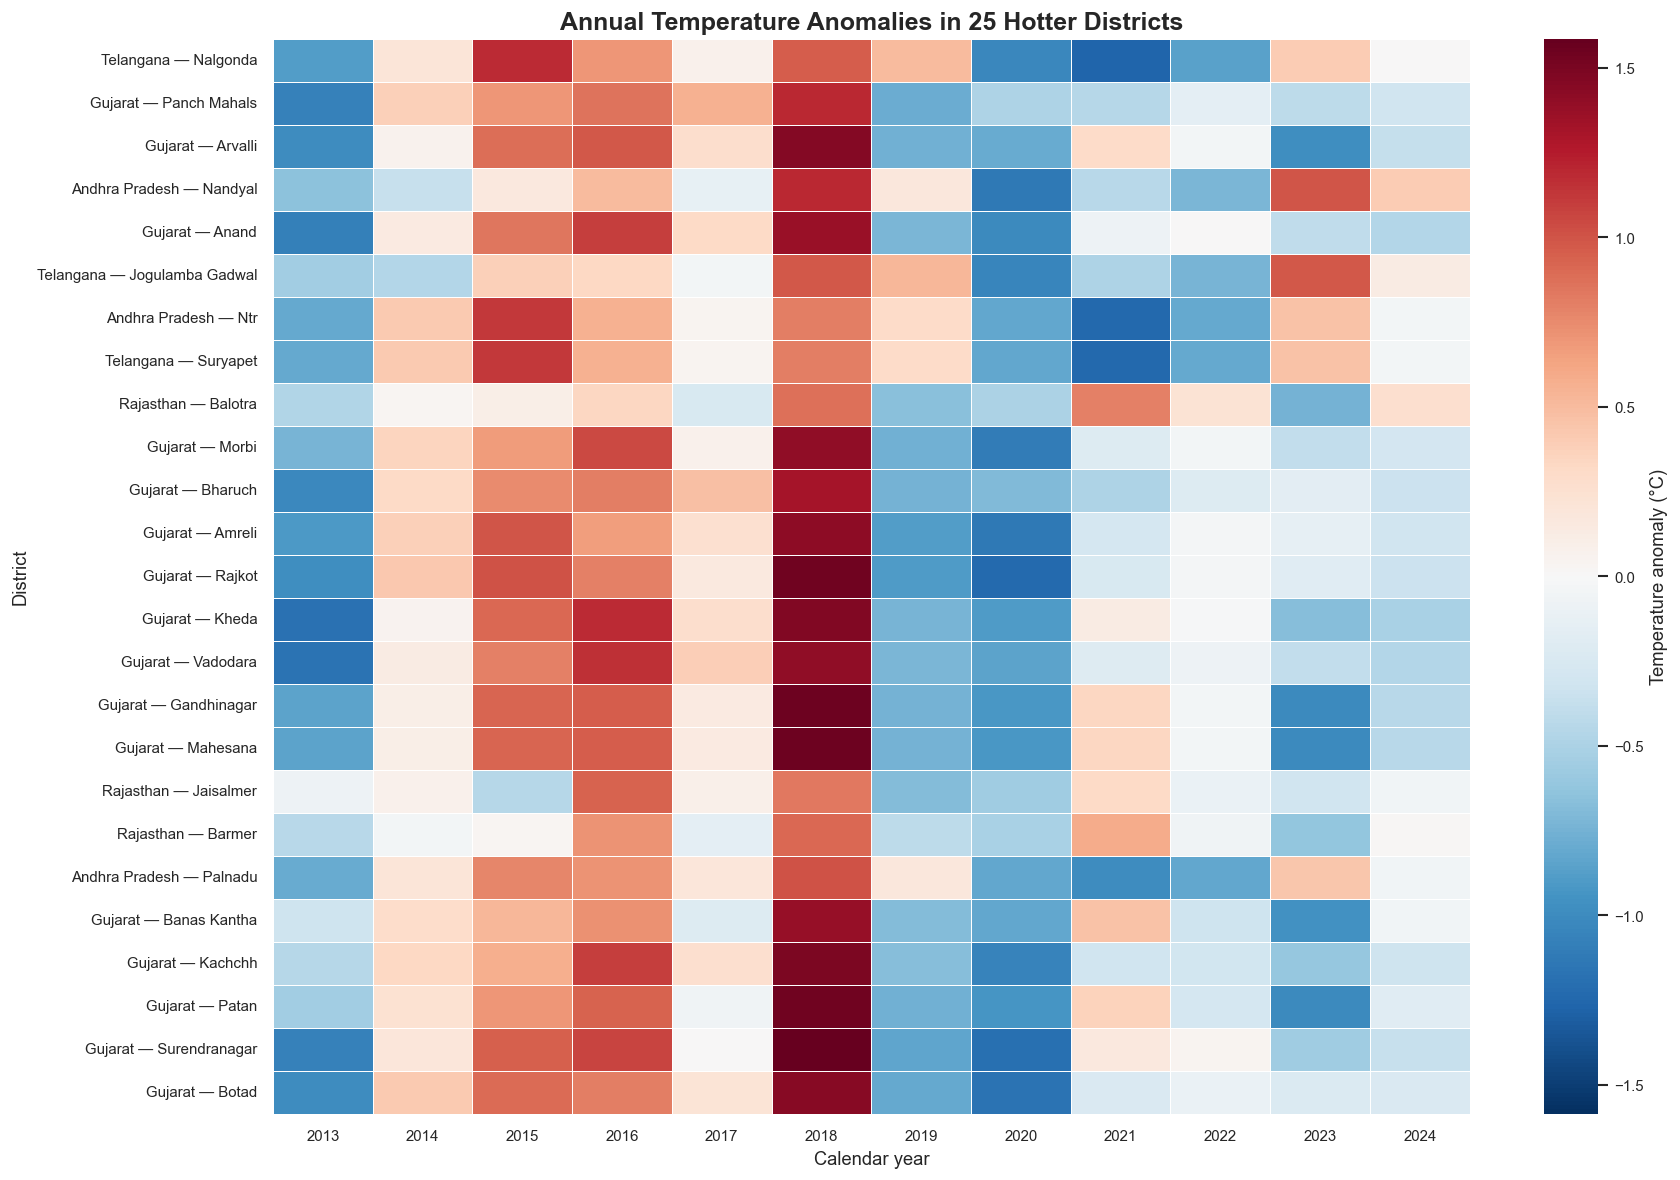

In [18]:
# Cell 16: District-level annual temperature anomalies

# Select the 25 districts with the highest long-term mean temperature.
top_districts = (
    weather_viz_df.groupby(["State", "District"])["tmax_mean_c"]
    .mean()
    .nlargest(25)
    .index
)

anomaly_df = weather_viz_df[
    weather_viz_df.set_index(["State", "District"]).index.isin(top_districts)
].copy()

# Identify each district unambiguously.
anomaly_df["district_label"] = (
    anomaly_df["State"] + " — " + anomaly_df["District"]
)

# Calculate each district's own long-term average.
district_baseline = anomaly_df.groupby("district_label")[
    "tmax_mean_c"
].transform("mean")

# Positive = warmer than its own baseline; negative = cooler.
anomaly_df["temperature_anomaly_c"] = (
    anomaly_df["tmax_mean_c"] - district_baseline
)

anomaly_pivot = anomaly_df.pivot(
    index="district_label",
    columns="calendar_year",
    values="temperature_anomaly_c"
)

# Sort districts by their average temperature for easier comparison.
district_order = (
    anomaly_df.groupby("district_label")["tmax_mean_c"]
    .mean()
    .sort_values()
    .index
)

anomaly_pivot = anomaly_pivot.loc[district_order]

# Use a symmetric color scale centered at zero.
limit = np.abs(anomaly_pivot.to_numpy()).max()

plt.figure(figsize=(15, 10))

sns.heatmap(
    anomaly_pivot,
    cmap="RdBu_r",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0.3,
    cbar_kws={"label": "Temperature anomaly (°C)"}
)

plt.title("Annual Temperature Anomalies in 25 Hotter Districts")
plt.xlabel("Calendar year")
plt.ylabel("District")
plt.tight_layout()
plt.show()

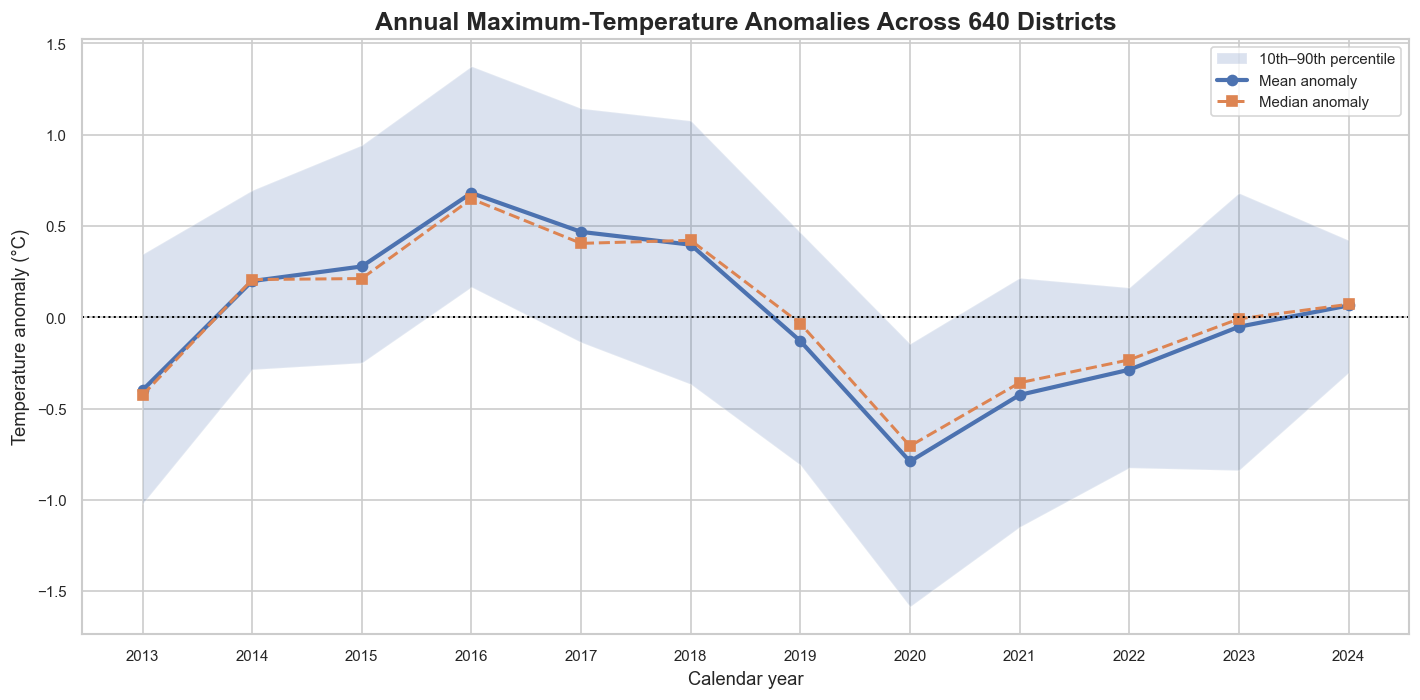

,calendar_year,mean_anomaly,median_anomaly,p10,p90
0,2013,-0.400,-0.427,-1.021,0.345
1,2014,0.198,0.206,-0.285,0.695
2,2015,0.278,0.212,-0.249,0.942
3,2016,0.680,0.648,0.166,1.374
4,2017,0.467,0.404,-0.137,1.144
5,2018,0.397,0.421,-0.366,1.076
6,2019,-0.130,-0.035,-0.808,0.464
7,2020,-0.790,-0.705,-1.584,-0.145
8,2021,-0.425,-0.359,-1.148,0.215
9,2022,-0.288,-0.233,-0.823,0.162


In [19]:
# Cell 17: Overall annual temperature anomaly across all districts

# Calculate each district's 2013–2024 baseline using all districts.
weather_viz_df["district_temp_baseline"] = (
    weather_viz_df.groupby("apy_geography_id")["tmax_mean_c"]
    .transform("mean")
)

weather_viz_df["temperature_anomaly_c"] = (
    weather_viz_df["tmax_mean_c"]
    - weather_viz_df["district_temp_baseline"]
)

# Summarize anomalies across all 640 districts for each year.
annual_anomaly_summary = (
    weather_viz_df.groupby("calendar_year")["temperature_anomaly_c"]
    .agg(
        mean_anomaly="mean",
        median_anomaly="median",
        p10=lambda x: x.quantile(0.10),
        p90=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.fill_between(
    annual_anomaly_summary["calendar_year"],
    annual_anomaly_summary["p10"],
    annual_anomaly_summary["p90"],
    alpha=0.2,
    label="10th–90th percentile"
)

plt.plot(
    annual_anomaly_summary["calendar_year"],
    annual_anomaly_summary["mean_anomaly"],
    marker="o",
    linewidth=2.5,
    label="Mean anomaly"
)

plt.plot(
    annual_anomaly_summary["calendar_year"],
    annual_anomaly_summary["median_anomaly"],
    marker="s",
    linestyle="--",
    linewidth=1.8,
    label="Median anomaly"
)

plt.axhline(0, color="black", linestyle=":", linewidth=1.2)

plt.title("Annual Maximum-Temperature Anomalies Across 640 Districts")
plt.xlabel("Calendar year")
plt.ylabel("Temperature anomaly (°C)")
plt.xticks(annual_anomaly_summary["calendar_year"])
plt.legend()
plt.tight_layout()
plt.show()

display(annual_anomaly_summary.round(3))

## Final Summary and Key Findings

### 1. Overview

This notebook visualizes district-level annual weather estimates across **640 districts in India from 2013 to 2024**. It examines temperature and precipitation trends, geographic variation, distributions, quality-control flags, relationships between weather variables, and district-level temperature anomalies.

### 2. Key Findings

- **Annual weather variation:** District-level average temperatures and precipitation vary across the observation period. These annual summaries describe year-to-year variation but do not, by themselves, establish a long-term climate trend.
- **Precipitation distribution:** Annual precipitation is right-skewed, with substantial differences between district-year records. Mean, median, percentile, and maximum comparisons help reveal this variability.
- **Geographic differences:** State-level boxplots show variation in annual precipitation, mean maximum temperature, and annual extreme maximum temperature across states and union territories.
- **Quality-control indicators:** The QC visualization highlights records flagged for extreme temperatures, high precipitation, extreme daily precipitation, and long district-to-grid distances. These flags identify observations requiring review; they do not automatically mean the measurements are invalid.
- **Temperature–precipitation relationship:** The scatterplot and correlation visualizations show an overall negative association in the analyzed data, with variation across states. This association does not establish causation.
- **District-level patterns:** Temperature heatmaps reveal differences in absolute temperature and year-to-year variation among the selected hotter districts.
- **Temperature anomalies:** Relative to each district's own 2013–2024 average, the annual anomaly summary shows positive mean anomalies during 2014–2018, the lowest mean anomaly in 2020, and a return close to the baseline by 2024.

### 3. Interpretation and Limitations

- The data represent **calendar-year weather summaries**, not crop-season or crop-growth-stage conditions.
- NASA POWER-derived estimates associated with representative grid points may not capture all local weather variation within a district.
- Multiple districts may share the same weather grid point, and district-to-grid distance can affect how representative the estimates are.
- The hotter-district heatmaps focus on a selected subset and should not be generalized to all districts.
- Temperature anomalies are calculated against the same 2013–2024 observation period. They are useful for relative comparison within this dataset but are not a substitute for a standard long-term climate baseline.
- Correlations and visual patterns are descriptive and do not establish causal relationships.

### 4. Conclusion

The visualizations provide complementary views of annual weather variability, geographic differences, precipitation extremes, quality-control indicators, and district-level temperature patterns. Together, they provide a visual foundation for subsequent analysis of agricultural conditions.

**Notebook status:** Weather data visualization completed for the current analysis scope. The notebook should be restarted and executed from beginning to end before being considered reproducible and final.